Объектов: 149 | Признаков: 29 (числовых=11, категориальных=18)
Цель: Давать кредит | классы: ['Да', 'Нет']

Наивный Байес (GaussianNB)
Матрица ошибок:
 [[12  0]
 [ 0 18]]

Отчёт по классам:
               precision    recall  f1-score   support

          Да       1.00      1.00      1.00        12
         Нет       1.00      1.00      1.00        18

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

ROC-AUC: 1.000
Accuracy: 1.000 | Precision: 1.000 | Recall: 1.000 | F1: 1.000

Линейный дискриминантный анализ (LDA)
Матрица ошибок:
 [[12  0]
 [ 0 18]]

Отчёт по классам:
               precision    recall  f1-score   support

          Да       1.00      1.00      1.00        12
         Нет       1.00      1.00      1.00        18

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00    

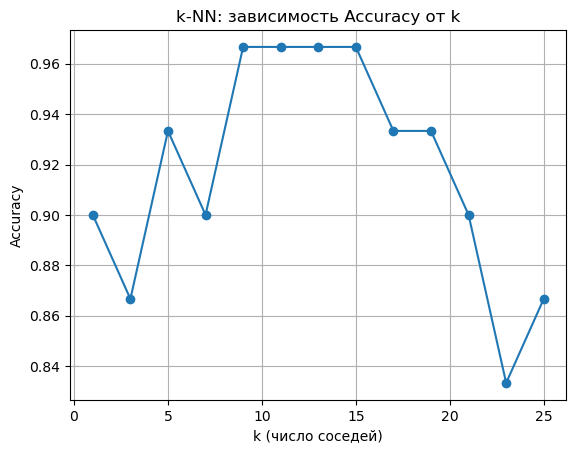


Лучший k по Accuracy: 9 (Accuracy=0.967)

k-ближайших соседей (k=9)
Матрица ошибок:
 [[11  1]
 [ 0 18]]

Отчёт по классам:
               precision    recall  f1-score   support

          Да       1.00      0.92      0.96        12
         Нет       0.95      1.00      0.97        18

    accuracy                           0.97        30
   macro avg       0.97      0.96      0.96        30
weighted avg       0.97      0.97      0.97        30

ROC-AUC: 1.000
Accuracy: 0.967 | Precision: 1.000 | Recall: 0.917 | F1: 0.957


<Figure size 640x480 with 0 Axes>

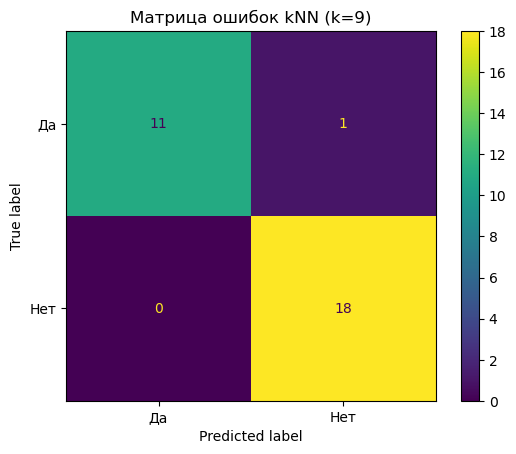

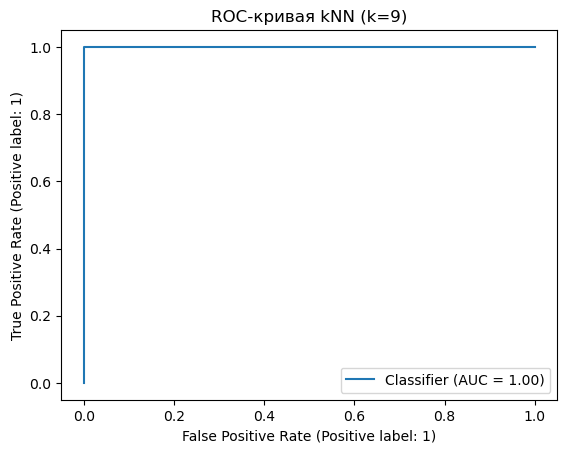

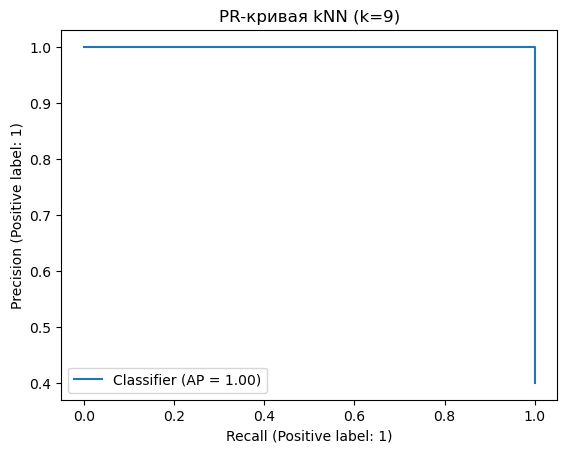


Метод опорных векторов (SVM, RBF)
Матрица ошибок:
 [[12  0]
 [ 0 18]]

Отчёт по классам:
               precision    recall  f1-score   support

          Да       1.00      1.00      1.00        12
         Нет       1.00      1.00      1.00        18

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

ROC-AUC: 1.000
Accuracy: 1.000 | Precision: 1.000 | Recall: 1.000 | F1: 1.000

Дерево решений
Матрица ошибок:
 [[12  0]
 [ 0 18]]

Отчёт по классам:
               precision    recall  f1-score   support

          Да       1.00      1.00      1.00        12
         Нет       1.00      1.00      1.00        18

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

Accuracy: 1.000 | Precision: 1.000 | Recall: 1.000 | F1: 1.000

Искусственная нейронная сеть (MLP)
Матриц

In [ ]:
## Ибрахим Фади БИ-3-23-01
# Решение задачи классификации для датасета «Кредит»

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
)

from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

RANDOM_STATE = 42

# 3.1 Анализ и предобработка данных

# Пути к данным: 
PATHS = [
    r"C:\Users\Fadi\Desktop\Учеба ВУЗ\Анализ данных\ПЗ4_27112025\ЗадачиКлассификации\Вариант4\Credit.txt",
    r"C:\Users\Fadi\Desktop\Учеба ВУЗ\Анализ данных\ПЗ4_27112025\ЗадачиКлассификации\Вариант4\Кредит.xlsx",
]

def read_credit(paths):
    for p in paths:
        if os.path.exists(p):
            if p.lower().endswith(".txt"):
                return pd.read_table(p, sep="\t", decimal=",", encoding="cp1251", engine="python")
            if p.lower().endswith((".xlsx", ".xls")):
                return pd.read_excel(p, dtype=str)
    raise FileNotFoundError("Не найден файл Credit.txt/Кредит.xlsx. Обнови список PATHS.")

df_raw = read_credit(PATHS).copy()

# Числоподобные строки переводим в числа (заменяем , на .)
def to_numeric_safe(s: pd.Series):
    if s.dtype == object:
        ss = s.str.replace(",", ".", regex=False)
        return pd.to_numeric(ss, errors="ignore")
    return s

df = df_raw.apply(to_numeric_safe)

# Ищем целевой столбец с классами Да/Нет
TARGET_CANDIDATES = ["Давать кредит", "Одобрение", "Решение", "Уход", "Target", "Class"]
target_col = next((c for c in TARGET_CANDIDATES if c in df.columns), None)
if target_col is None:
    raise ValueError("Не найден целевой столбец. Переименуй его, например, в «Давать кредит».")

# Как в методичке: считаем первые 6 колонок служебными и удаляем их
DROP_FIRST_N = 6
service_cols = [c for i, c in enumerate(df.columns) if i < DROP_FIRST_N and c != target_col]
X_all = df.drop(columns=service_cols)

# Цель и признаки
y = X_all[target_col].astype("category")
X = X_all.drop(columns=[target_col])

# Разметка типов признаков
num_cols = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
cat_cols = [c for c in X.columns if c not in num_cols]

print(f"Объектов: {len(df)} | Признаков: {X.shape[1]} (числовых={len(num_cols)}, категориальных={len(cat_cols)})")
print(f"Цель: {target_col} | классы: {list(y.unique())}")

# Разбиение на обучающую/тестовую выборки со стратификацией по целевому классу
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

# Препроцессинг для методов, чувствительных к масштабу: медианная импутация + стандартизация + OHE
preproc_scaled = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imp", SimpleImputer(strategy="median")),
            ("sc", StandardScaler()),
        ]), num_cols),
        ("cat", Pipeline([
            ("imp", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), cat_cols),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

# Препроцессинг для деревьев/ансамблей: импутация + OHE (без стандартизации)
preproc_tree = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), num_cols),
        ("cat", Pipeline([
            ("imp", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), cat_cols),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

# Функция отображения метрик
POS_LABEL = "Да" if "Да" in list(y.cat.categories) else y.cat.categories[-1]

def evaluate(model_name, y_true, y_pred, y_proba=None, pos_label=POS_LABEL):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, pos_label=pos_label, zero_division=0)
    rec = recall_score(y_true, y_pred, pos_label=pos_label, zero_division=0)
    f1 = f1_score(y_true, y_pred, pos_label=pos_label, zero_division=0)
    print(f"\n{model_name}")
    print("Матрица ошибок:\n", confusion_matrix(y_true, y_pred))
    print("\nОтчёт по классам:\n", classification_report(y_true, y_pred, zero_division=0))
    if y_proba is not None:
        try:
            auc = roc_auc_score((y_true == pos_label).astype(int), y_proba)
            print(f"ROC-AUC: {auc:.3f}")
        except Exception:
            pass
    print(f"Accuracy: {acc:.3f} | Precision: {prec:.3f} | Recall: {rec:.3f} | F1: {f1:.3f}")

# 3.2 Наивный байесовский метод
pipe_nb = Pipeline([
    ("prep", preproc_scaled),
    ("clf", GaussianNB()),
])
pipe_nb.fit(X_train, y_train)
pred_nb = pipe_nb.predict(X_test)
proba_nb = pipe_nb.predict_proba(X_test)[:, list(pipe_nb.classes_).index(POS_LABEL)]
evaluate("Наивный Байес (GaussianNB)", y_test, pred_nb, proba_nb)

# 3.3 Линейный дискриминантный анализ
pipe_lda = Pipeline([
    ("prep", preproc_scaled),
    ("clf", LinearDiscriminantAnalysis()),
])
pipe_lda.fit(X_train, y_train)
pred_lda = pipe_lda.predict(X_test)
proba_lda = pipe_lda.predict_proba(X_test)[:, list(pipe_lda.classes_).index(POS_LABEL)]
evaluate("Линейный дискриминантный анализ (LDA)", y_test, pred_lda, proba_lda)

# 3.4 Метод k-ближайших соседей с диаграммами
k_values = list(range(1, 26, 2))  # нечётные k от 1 до 25
acc_values = []
for k in k_values:
    pipe_knn_tune = Pipeline([
        ("prep", preproc_scaled),
        ("clf", KNeighborsClassifier(n_neighbors=k))
    ])
    pipe_knn_tune.fit(X_train, y_train)
    pred_k = pipe_knn_tune.predict(X_test)
    acc_values.append(accuracy_score(y_test, pred_k))

plt.figure()
plt.plot(k_values, acc_values, marker="o")
plt.title("k-NN: зависимость Accuracy от k")
plt.xlabel("k (число соседей)")
plt.ylabel("Accuracy")
plt.grid(True)
plt.show()

best_k = k_values[int(np.argmax(acc_values))]
print(f"\nЛучший k по Accuracy: {best_k} (Accuracy={max(acc_values):.3f})")

pipe_knn = Pipeline([
    ("prep", preproc_scaled),
    ("clf", KNeighborsClassifier(n_neighbors=best_k))
])
pipe_knn.fit(X_train, y_train)
pred_knn = pipe_knn.predict(X_test)
proba_knn = pipe_knn.predict_proba(X_test)[:, list(pipe_knn.classes_).index(POS_LABEL)]
evaluate(f"k-ближайших соседей (k={best_k})", y_test, pred_knn, proba_knn)

cm = confusion_matrix(y_test, pred_knn, labels=pipe_knn.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=pipe_knn.classes_)
plt.figure()
disp.plot(values_format="d")
plt.title(f"Матрица ошибок kNN (k={best_k})")
plt.show()

RocCurveDisplay.from_predictions((y_test == POS_LABEL).astype(int), proba_knn)
plt.title(f"ROC-кривая kNN (k={best_k})")
plt.show()

PrecisionRecallDisplay.from_predictions((y_test == POS_LABEL).astype(int), proba_knn)
plt.title(f"PR-кривая kNN (k={best_k})")
plt.show()

# 3.5 Метод опорных векторов
pipe_svm = Pipeline([
    ("prep", preproc_scaled),
    ("clf", SVC(kernel="rbf", C=1.0, gamma="scale", probability=True, random_state=RANDOM_STATE)),
])
pipe_svm.fit(X_train, y_train)
pred_svm = pipe_svm.predict(X_test)
proba_svm = pipe_svm.predict_proba(X_test)[:, list(pipe_svm.classes_).index(POS_LABEL)]
evaluate("Метод опорных векторов (SVM, RBF)", y_test, pred_svm, proba_svm)

# 3.6 Деревья решений
pipe_tree = Pipeline([
    ("prep", preproc_tree),
    ("clf", DecisionTreeClassifier(max_depth=6, min_samples_leaf=10, random_state=RANDOM_STATE)),
])
pipe_tree.fit(X_train, y_train)
pred_tree = pipe_tree.predict(X_test)
evaluate("Дерево решений", y_test, pred_tree)

# 3.7 Искусственные нейронные сети
pipe_mlp = Pipeline([
    ("prep", preproc_scaled),
    ("clf", MLPClassifier(hidden_layer_sizes=(64, 32),
                          activation="relu", solver="adam",
                          max_iter=1000, random_state=RANDOM_STATE)),
])
pipe_mlp.fit(X_train, y_train)
pred_mlp = pipe_mlp.predict(X_test)
proba_mlp = pipe_mlp.predict_proba(X_test)[:, list(pipe_mlp.classes_).index(POS_LABEL)]
evaluate("Искусственная нейронная сеть (MLP)", y_test, pred_mlp, proba_mlp)

# 3.8 Ансамблевые методы: Random Forest и AdaBoost
pipe_rf = Pipeline([
    ("prep", preproc_tree),
    ("clf", RandomForestClassifier(
        n_estimators=300, max_depth=None, min_samples_leaf=3,
        n_jobs=-1, random_state=RANDOM_STATE
    )),
])
pipe_rf.fit(X_train, y_train)
pred_rf = pipe_rf.predict(X_test)
evaluate("Random Forest", y_test, pred_rf)

pipe_ada = Pipeline([
    ("prep", preproc_tree),
    ("clf", AdaBoostClassifier(n_estimators=200, learning_rate=0.5, random_state=RANDOM_STATE)),
])
pipe_ada.fit(X_train, y_train)
pred_ada = pipe_ada.predict(X_test)
evaluate("AdaBoost", y_test, pred_ada)

# Сводка точностей по всем методам, чтобы выбрать лучший
summary = {
    "Naive Bayes": accuracy_score(y_test, pred_nb),
    "LDA": accuracy_score(y_test, pred_lda),
    f"kNN (k={best_k})": accuracy_score(y_test, pred_knn),
    "SVM (RBF)": accuracy_score(y_test, pred_svm),
    "Decision Tree": accuracy_score(y_test, pred_tree),
    "MLP": accuracy_score(y_test, pred_mlp),
    "Random Forest": accuracy_score(y_test, pred_rf),
    "AdaBoost": accuracy_score(y_test, pred_ada),
}
print("\nСводка Accuracy:")
for name, acc in sorted(summary.items(), key=lambda kv: kv[1], reverse=True):
    print(f"{name:>14}: {acc:.3f}")

